# Saqshy · Сақшы: tomorrow's wildfire risk map for Kazakhstan

**Track:** AI + Climate · **Team:** Dariya

**One-sentence pitch:** Saqshy helps rangers and district emergency services in Kazakhstan decide where to patrol tomorrow, by taking tonight's NASA satellite fire detections and weather for 1,326 squares of the country and giving back tomorrow's fire risk for every square, with the riskiest 10% as a red zone and a Kazakh/Russian alert.

*This is a prototype, not an official warning service.*

**How to run:** Runtime → Run all. It takes about 5–10 minutes in Colab. It rebuilds the dataset from the packed NASA files in `data/packed/`, retrains the model and re-runs every test. No API keys are needed. To download the raw data again, run `get_fires.sh` and `get_weather.py`.

**Website with the replay of every test day:** https://dede-bebe-lele.github.io/saqshy/

In [1]:
# Setup (Colab): get the code and data
import os
if not os.path.exists("train_eval.py"):
    !git clone -q https://github.com/dede-bebe-lele/saqshy saqshy
    %cd saqshy
    !pip -q install scikit-learn pandas pyarrow matplotlib joblib scipy
import glob
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200)

## 1. The data

* **NASA FIRMS, VIIRS S-NPP (375 m):** every active fire the satellite saw over Kazakhstan from 2012 to 2025. We keep vegetation fires (`type` 0) and drop low-confidence points.
* **NASA POWER:** daily weather for each of the 1,326 squares: temperature, humidity, wind, rain, and soil wetness.

Let's look at the fires first.

1,351,452 vegetation-fire detections, 2012-2025


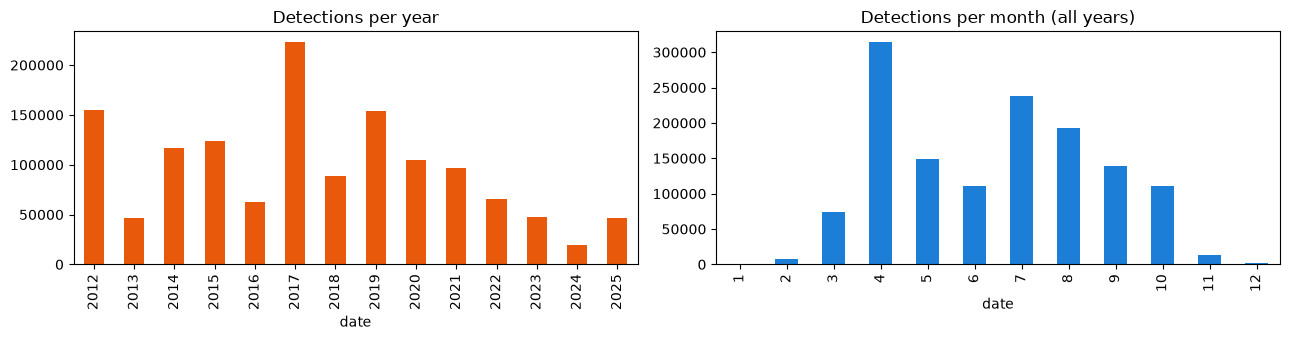

In [2]:
fires = pd.concat([pd.read_parquet(f) for f in sorted(glob.glob("data/packed/fires_*.parquet"))])
fires["date"] = pd.to_datetime(fires.acq_date)
print(f"{len(fires):,} vegetation-fire detections, 2012-2025")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
fires.groupby(fires.date.dt.year).size().plot.bar(ax=ax[0], color="#e8590c", title="Detections per year")
fires.groupby(fires.date.dt.month).size().plot.bar(ax=ax[1], color="#1c7ed6", title="Detections per month (all years)")
plt.tight_layout(); plt.show()

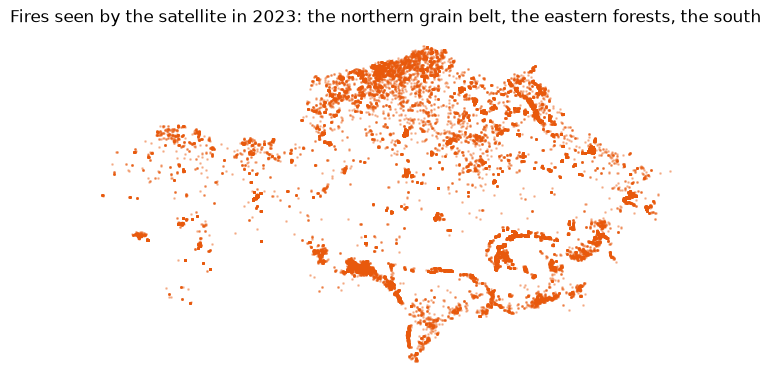

In [3]:
# where fires happen: one dot per detection in 2023 (a sample)
s = fires[fires.date.dt.year == 2023].sample(40000, random_state=0)
plt.figure(figsize=(11, 4.5))
plt.scatter(s.longitude, s.latitude, s=1, c="#e8590c", alpha=.3)
plt.title("Fires seen by the satellite in 2023: the northern grain belt, the eastern forests, the south")
plt.gca().set_aspect(1 / 0.67); plt.axis("off"); plt.show()

## 2. Build the dataset: one row per square per evening

`build_dataset.py` makes a row for every square and every evening of the fire season (March–November). Each row has only what is known **on the evening of day t**:

* today's weather, rain over 7 and 30 days, days since rain;
* the two standard fire-danger indices computed from that weather: the **Canadian Fire Weather Index** (used by Europe's EFFIS) and the **Nesterov index** (official in Russia);
* fires in the square today and over the last 3, 7, 30 and 365 days; fires in neighbouring squares;
* the square's usual fire rate for this month, using **earlier years only**;
* position and time of year.

The target is whether the satellite sees a fire in the square **tomorrow**.

In [4]:
!python -W ignore build_dataset.py
df = pd.read_parquet("data/dataset.parquet")
print(df.shape)
df.sample(5, random_state=1)[["date", "cell", "tmax", "rh_afternoon", "wind", "rain_7d", "fwi", "fires_today", "fire_days_365d", "clim_month", "fire_tomorrow"]]

zsh:1: command not found: python


(5105100, 40)


,date,cell,tmax,rh_afternoon,wind,rain_7d,fwi,fires_today,fire_days_365d,clim_month,fire_tomorrow
4475848,2024-05-15,47.75_73.75,28.709999,32.154373,3.07,7.130127,30.991667,0.0,0.0,0.002688,0
2360213,2018-07-08,53.25_72.75,32.049999,35.723438,1.74,0.950195,28.637890,0.0,1.0,0.043011,0
2382104,2018-07-25,47.75_78.75,22.030001,31.424013,3.17,4.250122,35.809242,0.0,3.0,0.016129,0
5103494,2025-11-29,50.75_66.25,0.890000,51.991119,1.89,1.600098,4.666312,0.0,4.0,0.000000,0
1923771,2017-05-15,50.75_78.75,17.670000,49.253109,4.46,3.190063,24.459793,0.0,3.0,0.012903,0


## 3. Train on 2012–2022, test on 2023–2025

`train_eval.py` trains gradient-boosted trees (`HistGradientBoostingClassifier`) on 2012–2022 and tests on **every day of three fire seasons it never saw**. Baselines:

1. **Recent fires:** rank squares by how many days they burned in the last week. This is what a dispatcher can do without AI.
2. **Usual for this month:** the square's historical fire rate.
3. **Nesterov index** and 4. **Canadian FWI:** the classic weather-only fire-danger indices.

**Main metric:** if rangers can watch only the riskiest 10% of the country tomorrow, what share of tomorrow's fires happen inside it?

In [5]:
!python -W ignore train_eval.py

zsh:1: command not found: python


In [6]:
res = pd.read_csv("results/scores_all_fires.csv")
res[["method", "fires caught in top 10%", "fires caught in top 5%", "ROC-AUC"]].round(3)

,method,fires caught in top 10%,fires caught in top 5%,ROC-AUC
0,Recent fires (last 7 days),0.618,0.463,0.875
1,Usual for this month,0.548,0.391,0.872
2,Nesterov index (used in Russia),0.112,0.057,0.551
3,Canadian FWI (used in Europe),0.113,0.054,0.532
4,"Saqshy, weather only",0.533,0.373,0.879
5,Saqshy,0.688,0.523,0.934


zsh:1: command not found: python


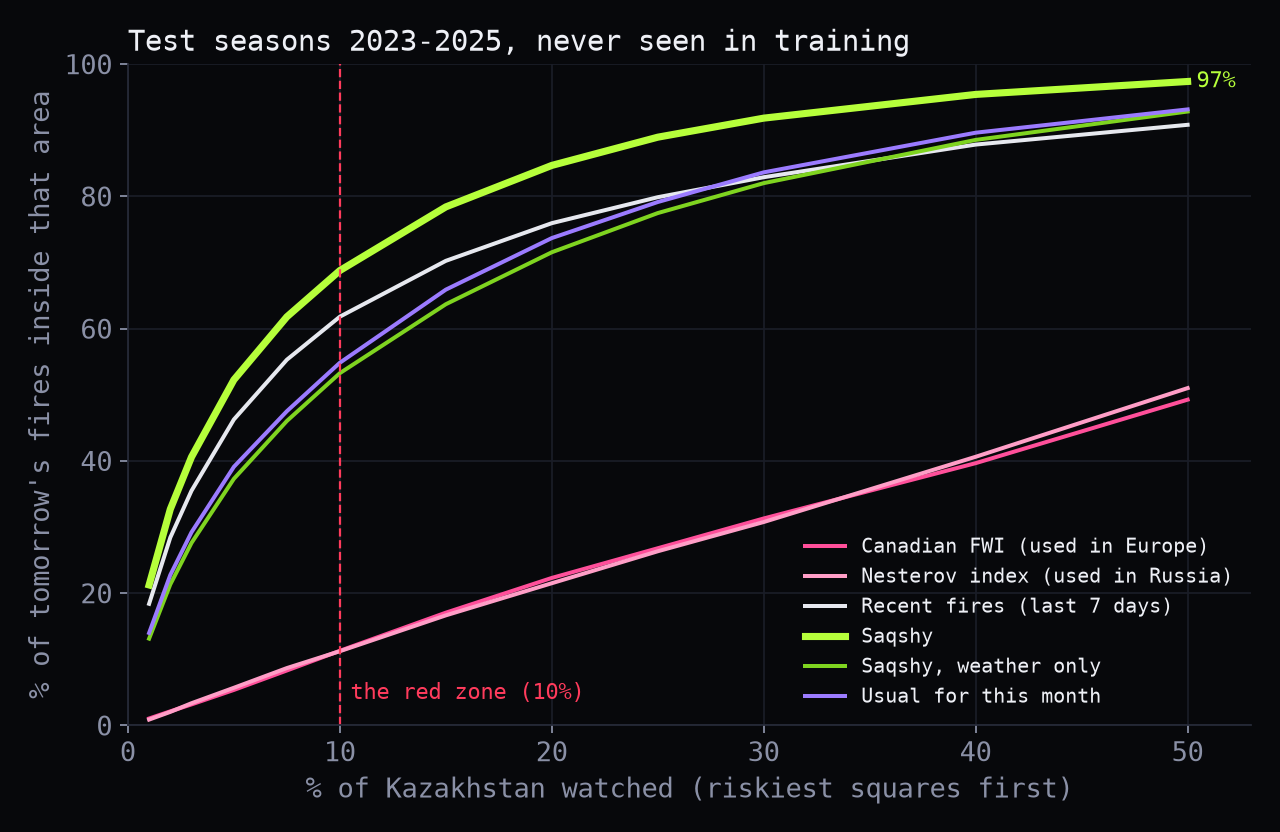

In [7]:
!python make_figures.py
display(Image("figures/tradeoff.png"))

**Takeaways**

* Saqshy puts **about 69% of tomorrow's fires inside 10% of the country**, against 62% for the best simple rule (recent fires).
* The weather-only indices (FWI, Nesterov) do badly here, at 11%. Their riskiest squares are the hot southern deserts, which have little to burn. Saqshy learns where the fuel is and where fires really start.

### Stress tests: is the lead real?

Most fires tomorrow are where fires burn today, so persistence is strong. `extra_checks.py` builds the fairest simple rule I could (recent fires + usual rate for the month, a logistic regression fitted on **2021-2022 only**), puts a bootstrap interval on Saqshy's lead, splits out the June-September wildfire season (fewer stubble burns), and gives the FWI a fairer chance (only squares that burned in the last year).

In [8]:
!python -W ignore extra_checks.py > /dev/null
import json
X = json.load(open("results/extra_checks.json"))
print("Top-10% catch:", {k: round(v, 3) for k, v in X["all_fires_top10"].items()})
print("New fires, top-10% catch:", {k: round(v, 3) for k, v in X["new_fires_top10"].items()})
print("95% bootstrap interval for Saqshy's lead (points):", X["bootstrap_95ci_points"])
print("Days (5+ fire squares) where Saqshy beats recent fires:", round(X["share_of_those_days_saqshy_beats_recent"], 3))
pd.read_csv("results/scores_by_season.csv").round(3)

zsh:1: command not found: python


Top-10% catch: {'Saqshy': 0.688, 'Recent fires + usual for month (fitted on 2021-22)': 0.659, 'Recent fires (last 7 days)': 0.618, 'Canadian FWI, only squares that burned in the last year': 0.239, 'Canadian FWI': 0.113}
New fires, top-10% catch: {'Saqshy': 0.425, 'Recent fires + usual for month (fitted on 2021-22)': 0.364, 'Recent fires (last 7 days)': 0.283, 'Canadian FWI, only squares that burned in the last year': 0.188, 'Canadian FWI': 0.087}
95% bootstrap interval for Saqshy's lead (points): {'Saqshy minus recent fires': [6.4, 7.6], 'Saqshy minus fair rule': [2.3, 3.4]}
Days (5+ fire squares) where Saqshy beats recent fires: 0.769


,season,method,fire square-days,caught in top 10%,new fires caught in top 10%
0,June-September (wildfire season),Saqshy,7311,0.700,0.464
1,June-September (wildfire season),Recent fires + usual for month (fitted on 2021...,7311,0.667,0.401
2,June-September (wildfire season),Recent fires (last 7 days),7311,0.610,0.294
3,June-September (wildfire season),"Canadian FWI, only squares that burned in the ...",7311,0.196,0.185
4,June-September (wildfire season),Canadian FWI,7311,0.084,0.086
5,March-May + October-November,Saqshy,15948,0.682,0.403
6,March-May + October-November,Recent fires + usual for month (fitted on 2021...,15948,0.656,0.343
7,March-May + October-November,Recent fires (last 7 days),15948,0.622,0.277
8,March-May + October-November,"Canadian FWI, only squares that burned in the ...",15948,0.259,0.190
9,March-May + October-November,Canadian FWI,15948,0.126,0.088


**Honest reading:** against the fair rule the lead is small (about +3 points, interval +2.3 to +3.4) but holds in the wildfire season and is bigger on new fires (42% vs 36%).

## 4. A real evening: 29 April 2025 (test season)

Squares with fire on 30 April: 82
  inside Saqshy's red 10%:       56
  inside 'recent fires' red 10%: 33
  inside the FWI's red 10%:      1


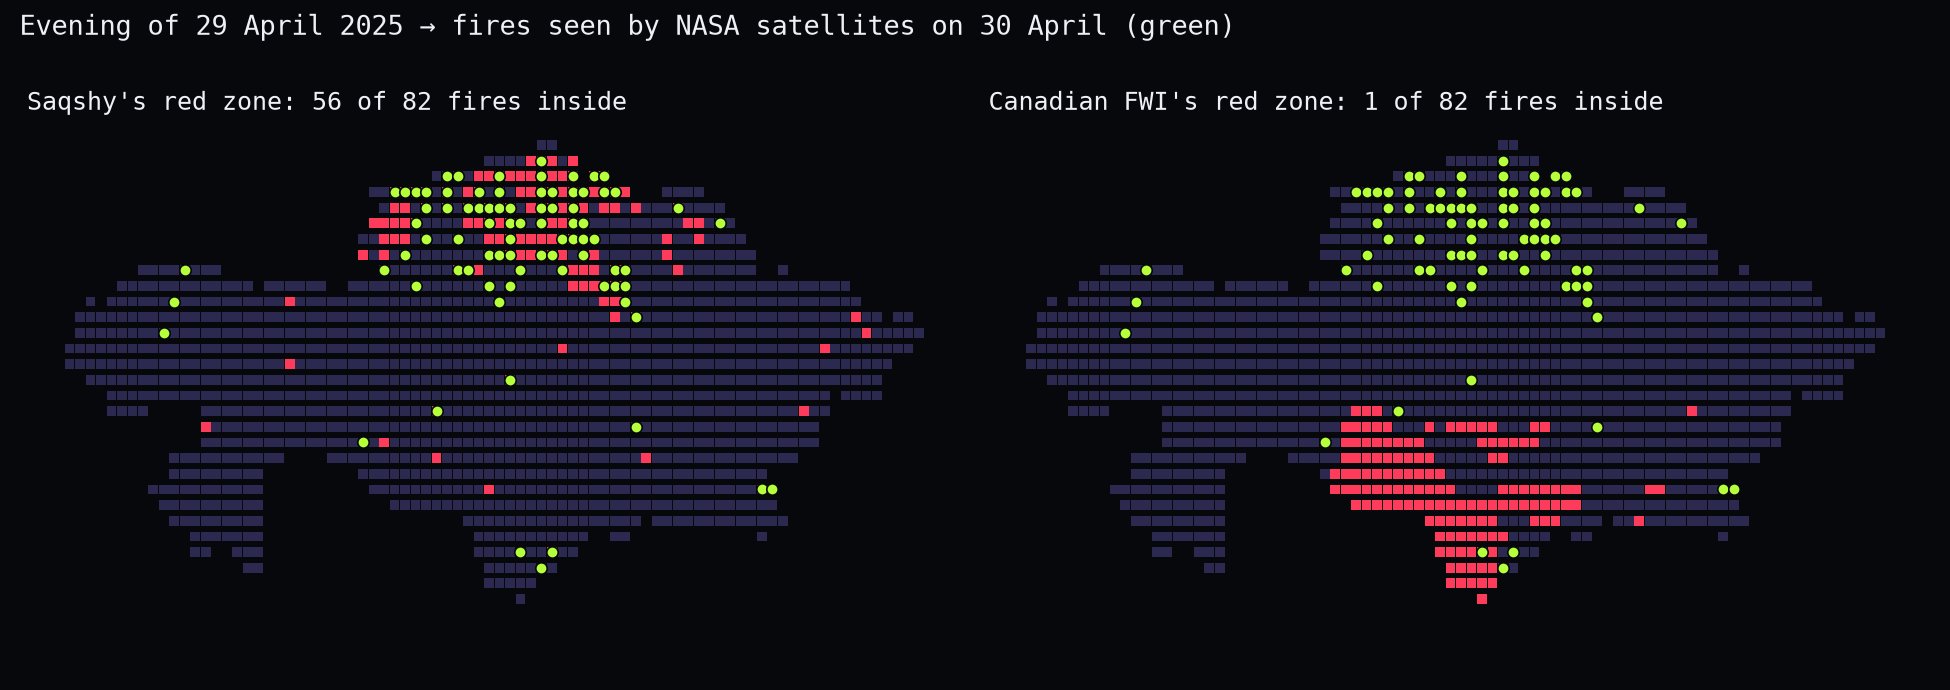

In [9]:
p = pd.read_parquet("results/test_predictions.parquet")
day = p[p.date == "2025-04-29"]
f = day[day.fire_tomorrow == 1]
recent_rank = day.fire_days_7d.rank(ascending=False, method="first", pct=True)
print(f"Squares with fire on 30 April: {len(f)}")
print(f"  inside Saqshy's red 10%:       {(f.risk_rank <= .1).sum()}")
print(f"  inside 'recent fires' red 10%: {(recent_rank[f.index] <= .1).sum()}")
print(f"  inside the FWI's red 10%:      {(f.fwi_rank <= .1).sum()}")
display(Image("figures/showcase_2025-04-29.png"))

## 5. Does it work everywhere, and every year?

In [10]:
print(pd.read_csv("results/scores_by_year.csv").round(3).to_string(index=False))
print()
print(pd.read_csv("results/fairness_by_region.csv").round(3).to_string(index=False))

 year                        method  fires  caught in top 10%  new fires caught in top 10%
 2023    Recent fires (last 7 days)   8715              0.613                        0.247
 2023 Canadian FWI (used in Europe)   8715              0.115                        0.084
 2023                        Saqshy   8715              0.675                        0.374
 2024    Recent fires (last 7 days)   5191              0.665                        0.380
 2024 Canadian FWI (used in Europe)   5191              0.145                        0.109
 2024                        Saqshy   5191              0.752                        0.552
 2025    Recent fires (last 7 days)   9353              0.596                        0.254
 2025 Canadian FWI (used in Europe)   9353              0.092                        0.077
 2025                        Saqshy   9353              0.664                        0.391

                             region  cells  fires  Saqshy  Canadian FWI  Recent fires  Sa

Saqshy beats the simple rule in every year and every region. It is weaker in the north (grain belt) and the east (forests), where fires are less regular than in the south.

## 6. Where it fails

In [11]:
# The Abai fire: lightning, 8 June 2023
ab = p[(p.date == "2023-06-07") & (p.cell == "50.75_80.75")].iloc[0]
nx = p[(p.date == "2023-06-08") & (p.cell == "50.75_80.75")].iloc[0]
print(f"Evening of 7 June: the square was in Saqshy's riskiest {ab.risk_rank:.0%} (outside the red zone). FWI: {ab.fwi_rank:.0%}")
print(f"Evening of 8 June, once burning: top {nx.risk_rank:.1%}")
new = pd.read_csv("results/scores_new_fires.csv")
print()
print("New fires only (no fire in the square in the 3 days before):")
print(new[["method", "fires caught in top 10%"]].round(3).to_string(index=False))

Evening of 7 June: the square was in Saqshy's riskiest 38% (outside the red zone). FWI: 50%
Evening of 8 June, once burning: top 0.1%

New fires only (no fire in the square in the 3 days before):
                         method  fires caught in top 10%
     Recent fires (last 7 days)                    0.283
           Usual for this month                    0.417
Nesterov index (used in Russia)                    0.095
  Canadian FWI (used in Europe)                    0.087
           Saqshy, weather only                    0.406
                         Saqshy                    0.425


* **It missed the start of the Abai fire.** A lightning strike leaves no trace in yesterday's data. Once the fire was burning, the square went straight into the top 1%.
* **New fires are much harder.** About 43% fall in the red zone, barely better than the usual-for-this-month rule (42%).
* **The satellite is the ground truth.** It misses small fires and fires under cloud, and some detections are farmers burning stubble.
* **Squares are coarse** (about 2,000 km²) because that is the resolution of the weather data.

**Next steps:** add lightning forecasts and land cover; run it live next spring with the previous day's FIRMS fires and send the alert to rangers through a Telegram bot.

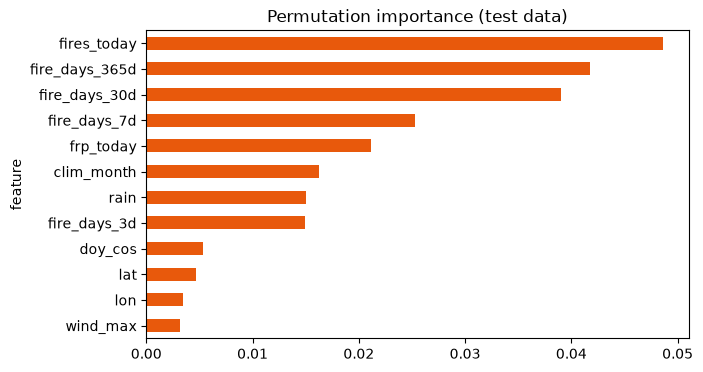

In [12]:
imp = pd.read_csv("results/feature_importance.csv").head(12)
imp.plot.barh(x="feature", y="importance", legend=False, figsize=(7, 4), color="#e8590c", title="Permutation importance (test data)")
plt.gca().invert_yaxis(); plt.show()

## Sources
NASA FIRMS (VIIRS S-NPP active fires) · NASA POWER daily weather · Natural Earth border (world.geo.json) · Van Wagner (1987) Canadian FWI · Nesterov index · scikit-learn, pandas, NumPy, SciPy, matplotlib · AI tools: Claude (Anthropic) helped with brainstorming, data search and code. Full list in the README.